# SortVision: Waste Image Classification

Multi-class classification of waste photos into six categories: cardboard,
glass, metal, paper, plastic, and trash (used as an Other / General
bucket).

Dataset: [TrashBusters/combined](https://huggingface.co/datasets/TrashBusters/combined)
on Hugging Face, a harmonized merge of four public waste image datasets,
29,849 images with a pre-made train, validation, and test split.

This notebook covers data loading, exploratory data analysis, a
from-scratch CNN, training curves, full test-set evaluation (accuracy,
macro and weighted precision/recall/F1, confusion matrix, per-class
performance, most confused class pairs), and Grad-CAM explainability.

**Before running:** `pip install -r ../requirements.txt`. The dataset
downloads automatically from Hugging Face the first time it is loaded, no
manual download or folder setup needed.

## 1. Setup

In [1]:
import os
import sys
sys.path.append(os.path.abspath(".."))  # so `import config` and `from src...` work from notebooks/

import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

import config
from src.data_loader import load_waste_dataset, get_class_names
from src.preprocessing import compute_class_weights
from src.dataset import make_dataset
from src.model import build_cnn_from_scratch, compile_model
from src.gradcam import compute_gradcam_heatmap, overlay_heatmap

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

np.random.seed(config.RANDOM_STATE)
tf.random.set_seed(config.RANDOM_STATE)

print("TensorFlow:", tf.__version__)
print("Target dataset:", config.HF_DATASET_NAME)

d:\sortvision\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.21.0
Target dataset: TrashBusters/combined


## 2. Load the dataset

Downloads from Hugging Face on first run, then uses the local cache on
later runs. No manual folder setup required, unlike a Kaggle zip.

In [2]:
ds = load_waste_dataset()

names = get_class_names(ds)
print("Splits:", {split: len(ds[split]) for split in ds})
print("Class names from dataset:", names)
print("Class names in config.py:", config.CLASS_NAMES)

if names != config.CLASS_NAMES:
    print("\nWARNING: dataset class order does not match config.CLASS_NAMES. "
          "Update config.py to match before trusting any results.")

Splits: {'train': 20894, 'validation': 4477, 'test': 4478}
Class names from dataset: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Class names in config.py: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


## 3. Exploratory Data Analysis

### 3.1 Class distribution

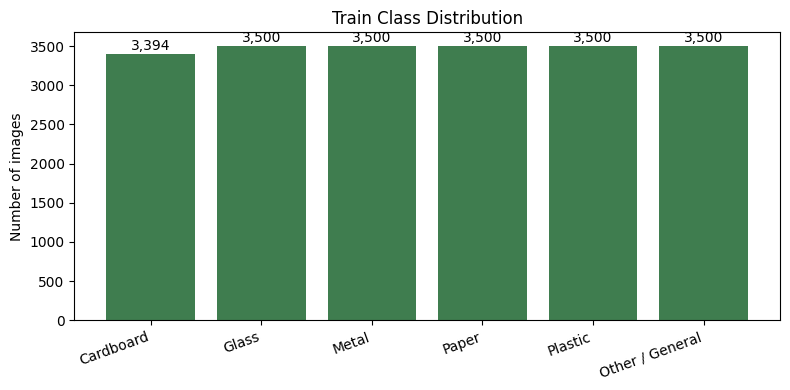

Class balance (train):
  Cardboard         3,394  ( 16.2%)
  Glass             3,500  ( 16.8%)
  Metal             3,500  ( 16.8%)
  Paper             3,500  ( 16.8%)
  Plastic           3,500  ( 16.8%)
  Other / General   3,500  ( 16.8%)


In [3]:
train_labels = ds["train"]["label"]
counts = collections.Counter(train_labels)
display_names = [config.DISPLAY_NAMES.get(n, n) for n in names]

plt.figure(figsize=(8, 4))
plt.bar(display_names, [counts.get(i, 0) for i in range(len(names))], color="#3F7D4F")
plt.title("Train Class Distribution")
plt.ylabel("Number of images")
plt.xticks(rotation=20, ha="right")
for i, name in enumerate(names):
    v = counts.get(i, 0)
    plt.text(i, v + 50, f"{v:,}", ha="center")
plt.tight_layout()
plt.savefig(os.path.join(config.OUTPUTS_DIR, "class_distribution.png"), dpi=150)
plt.show()

print("Class balance (train):")
total = len(train_labels)
for i, name in enumerate(names):
    print(f"  {config.DISPLAY_NAMES.get(name, name):16s} {counts.get(i,0):6,}  ({100*counts.get(i,0)/total:5.1f}%)")

### 3.2 Sample images

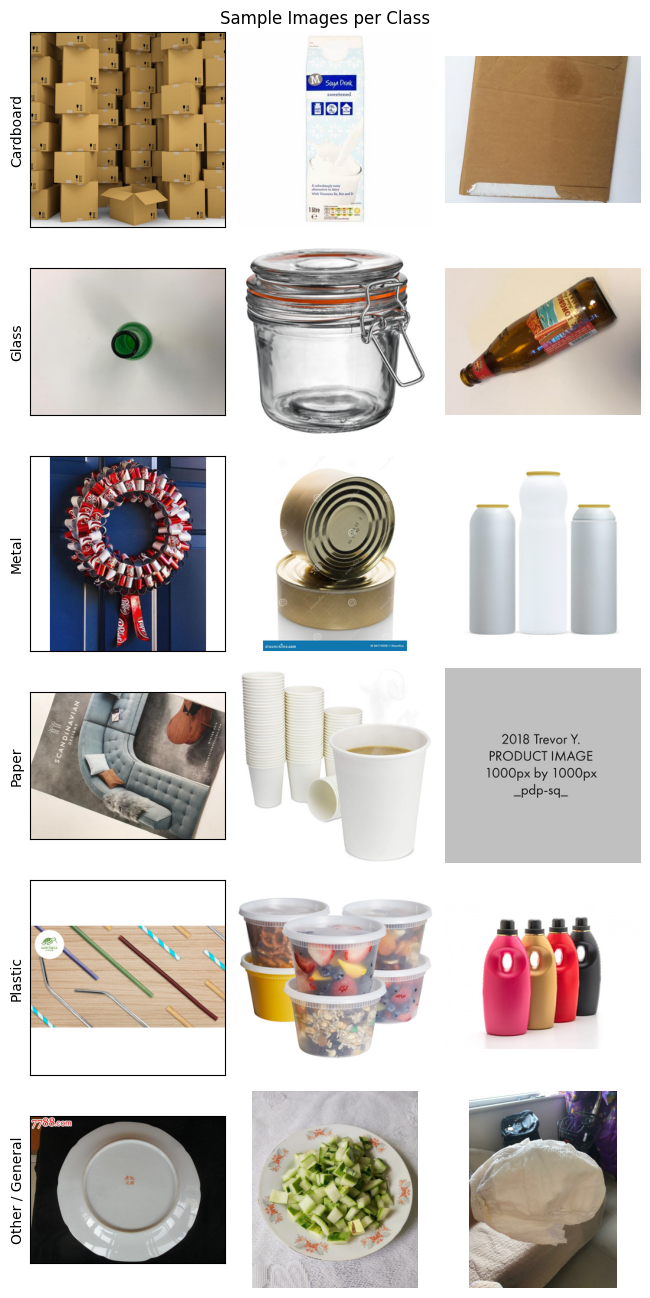

In [4]:
def show_sample_images(ds_split, class_names, display_names, n_per_class=3):
    fig, axes = plt.subplots(len(class_names), n_per_class, figsize=(2.2 * n_per_class, 2.2 * len(class_names)))
    labels_arr = np.array(ds_split["label"])
    for row, cls_idx in enumerate(range(len(class_names))):
        idxs = np.where(labels_arr == cls_idx)[0]
        chosen = np.random.choice(idxs, size=min(n_per_class, len(idxs)), replace=False)
        for col, idx in enumerate(chosen):
            img = ds_split[int(idx)]["image"]
            axes[row, col].imshow(img)
            axes[row, col].axis("off")
        axes[row, 0].set_ylabel(display_names[row], fontsize=10)
        axes[row, 0].axis("on")
        axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    plt.suptitle("Sample Images per Class")
    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUTS_DIR, "sample_images.png"), dpi=150)
    plt.show()

show_sample_images(ds["train"], names, display_names)

## 4. Build the tf.data pipelines

For a fast CPU run, subsample the training and validation sets. Set
`MAX_TRAIN_SAMPLES` and `MAX_VAL_SAMPLES` to `None` for the full dataset
on a GPU.

In [6]:
MAX_TRAIN_SAMPLES = 5000
MAX_VAL_SAMPLES = 1000

train_split = ds["train"]
val_split = ds["validation"]
test_split = ds["test"]

if MAX_TRAIN_SAMPLES and len(train_split) > MAX_TRAIN_SAMPLES:
    train_split = train_split.shuffle(seed=config.RANDOM_STATE).select(range(MAX_TRAIN_SAMPLES))
if MAX_VAL_SAMPLES and len(val_split) > MAX_VAL_SAMPLES:
    val_split = val_split.shuffle(seed=config.RANDOM_STATE).select(range(MAX_VAL_SAMPLES))

print(f"Using for this run -> Train: {len(train_split):,}  Val: {len(val_split):,}  Test (untouched): {len(test_split):,}")

train_ds = make_dataset(train_split, config.IMAGE_SIZE, config.BATCH_SIZE, config.NUM_CLASSES, training=True)
val_ds = make_dataset(val_split, config.IMAGE_SIZE, config.BATCH_SIZE, config.NUM_CLASSES, training=False)
test_ds = make_dataset(test_split, config.IMAGE_SIZE, config.BATCH_SIZE, config.NUM_CLASSES, training=False)

Using for this run -> Train: 5,000  Val: 1,000  Test (untouched): 4,478


## 5. Build the model

In [7]:
model = build_cnn_from_scratch(config.NUM_CLASSES, config.IMAGE_SIZE, config.CHANNELS)
model = compile_model(model, config.LEARNING_RATE)
model.summary()

Model: "sortvision_cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 457,670 (1.75 MB)

 Trainable params: 456,710 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

In [8]:
class_weights = compute_class_weights(train_split["label"], config.NUM_CLASSES)
print("Class weights:", class_weights)

Class weights: {0: 1.013787510137875, 1: 0.9992006394884093, 2: 1.007658202337767, 3: 0.9746588693957114, 4: 1.0004001600640255, 5: 1.0052271813429836}


## 6. Train

In [9]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy", mode="max",
        patience=config.EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_accuracy", mode="max",
        factor=config.REDUCE_LR_FACTOR,
        patience=config.REDUCE_LR_PATIENCE,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=config.EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
)

model.save(config.CNN_MODEL_PATH)
print(f"Saved trained model to {config.CNN_MODEL_PATH}")

Epoch 1/30


d:\sortvision\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


     56/Unknown 162s 3s/step - accuracy: 0.3092 - auc: 0.6597 - loss: 1.8520

d:\sortvision\venv\Lib\site-packages\PIL\Image.py:1056: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


    157/Unknown 398s 2s/step - accuracy: 0.3340 - auc: 0.6823 - loss: 1.7599

d:\sortvision\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


157/157 ━━━━━━━━━━━━━━━━━━━━ 413s 2s/step - accuracy: 0.3340 - auc: 0.6823 - loss: 1.7599 - val_accuracy: 0.2040 - val_auc: 0.5788 - val_loss: 1.9599 - learning_rate: 0.0010
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 438s 3s/step - accuracy: 0.4052 - auc: 0.7390 - loss: 1.5575 - val_accuracy: 0.3270 - val_auc: 0.6716 - val_loss: 1.7265 - learning_rate: 0.0010
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 376s 2s/step - accuracy: 0.4268 - auc: 0.7652 - loss: 1.4786 - val_accuracy: 0.3080 - val_auc: 0.6669 - val_loss: 1.7275 - learning_rate: 0.0010
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 493s 3s/step - accuracy: 0.4428 - auc: 0.7770 - loss: 1.4425 - val_accuracy: 0.4430 - val_auc: 0.7599 - val_loss: 1.5733 - learning_rate: 0.0010
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 534s 3s/step - accuracy: 0.4638 - auc: 0.7864 - loss: 1.4199 - val_accuracy: 0.4520 - val_auc: 0.7708 - val_loss: 1.4577 - learning_rate: 0.0010
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 454s 3s/step - accuracy: 0.4842 - auc: 0.7976 

## 7. Training curves: accuracy, loss, AUC

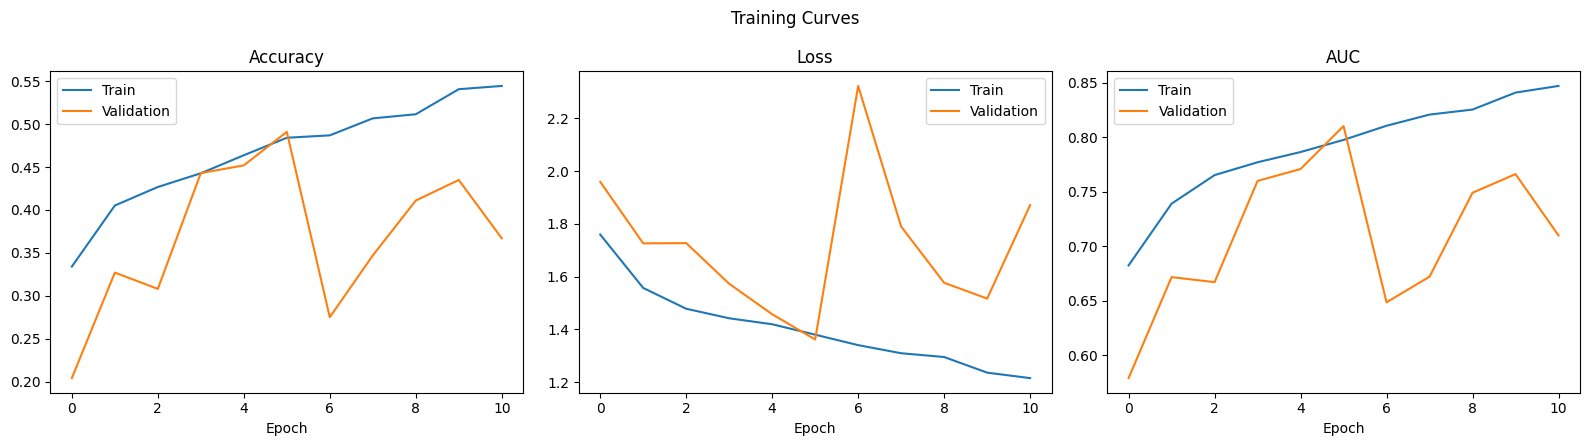

Training ran 11 epochs, best val_accuracy at epoch 6
Best val_accuracy: 0.4910


In [10]:
hist_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(hist_df["accuracy"], label="Train")
axes[0].plot(hist_df["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(hist_df["loss"], label="Train")
axes[1].plot(hist_df["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

axes[2].plot(hist_df["auc"], label="Train")
axes[2].plot(hist_df["val_auc"], label="Validation")
axes[2].set_title("AUC")
axes[2].set_xlabel("Epoch")
axes[2].legend()

plt.suptitle("Training Curves")
plt.tight_layout()
plt.savefig(os.path.join(config.OUTPUTS_DIR, "training_curves.png"), dpi=150)
plt.show()

best_epoch = int(hist_df["val_accuracy"].idxmax()) + 1
print(f"Training ran {len(hist_df)} epochs, best val_accuracy at epoch {best_epoch}")
print(f"Best val_accuracy: {hist_df['val_accuracy'].max():.4f}")

## 8. Test set evaluation (untouched)

In [11]:
y_true = np.array(test_split["label"])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

acc = accuracy_score(y_true, y_pred)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

print(f"Accuracy: {acc:.4f}")
print(f"Macro    precision/recall/F1: {precision_macro:.4f} / {recall_macro:.4f} / {f1_macro:.4f}")
print(f"Weighted precision/recall/F1: {precision_weighted:.4f} / {recall_weighted:.4f} / {f1_weighted:.4f}")
print()
print(classification_report(y_true, y_pred, target_names=display_names, zero_division=0))

140/140 ━━━━━━━━━━━━━━━━━━━━ 64s 451ms/step


d:\sortvision\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Accuracy: 0.4875
Macro    precision/recall/F1: 0.4866 / 0.4885 / 0.4821
Weighted precision/recall/F1: 0.4864 / 0.4875 / 0.4815

                 precision    recall  f1-score   support

      Cardboard       0.53      0.70      0.60       728
          Glass       0.48      0.60      0.53       750
          Metal       0.41      0.43      0.42       750
          Paper       0.47      0.38      0.42       750
        Plastic       0.47      0.35      0.40       750
Other / General       0.56      0.48      0.51       750

       accuracy                           0.49      4478
      macro avg       0.49      0.49      0.48      4478
   weighted avg       0.49      0.49      0.48      4478



### 8.1 Confusion matrix

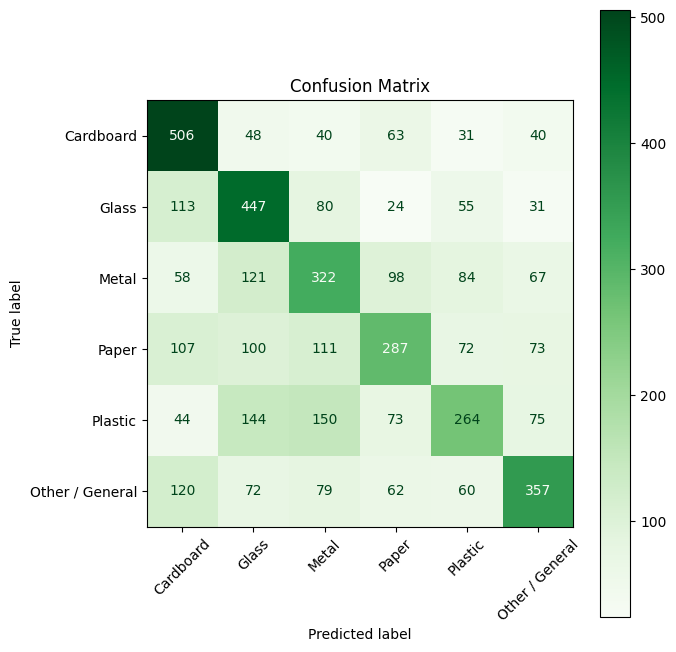

In [12]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7, 7))
disp = ConfusionMatrixDisplay(cm, display_labels=display_names)
disp.plot(cmap="Greens", ax=ax, xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(config.OUTPUTS_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

### 8.2 Per-class performance

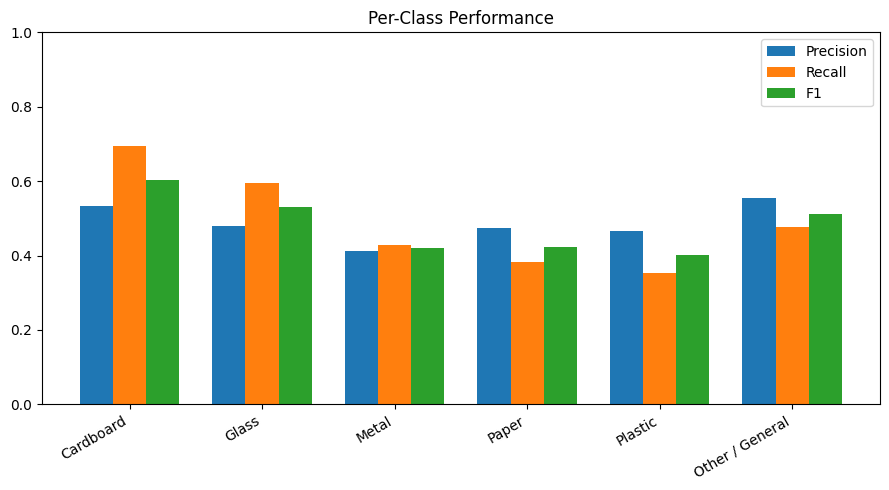

In [13]:
precision_per, recall_per, f1_per, support_per = precision_recall_fscore_support(y_true, y_pred, zero_division=0)

x = np.arange(len(display_names))
width = 0.25
plt.figure(figsize=(9, 5))
plt.bar(x - width, precision_per, width, label="Precision")
plt.bar(x, recall_per, width, label="Recall")
plt.bar(x + width, f1_per, width, label="F1")
plt.xticks(x, display_names, rotation=30, ha="right")
plt.ylim(0, 1)
plt.title("Per-Class Performance")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(config.OUTPUTS_DIR, "per_class_performance.png"), dpi=150)
plt.show()

### 8.3 Most confused class pairs

In [14]:
def most_confused_pairs(cm, class_names, top_n=5):
    pairs = []
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if i != j and cm[i, j] > 0:
                pairs.append((class_names[i], class_names[j], int(cm[i, j])))
    pairs.sort(key=lambda p: p[2], reverse=True)
    return pairs[:top_n]

confused = most_confused_pairs(cm, display_names)
print("Most confused class pairs (true -> predicted, count):")
for true_cls, pred_cls, count in confused:
    print(f"  {true_cls} -> {pred_cls}: {count}")

Most confused class pairs (true -> predicted, count):
  Plastic -> Metal: 150
  Plastic -> Glass: 144
  Metal -> Glass: 121
  Other / General -> Cardboard: 120
  Glass -> Cardboard: 113


## 9. Grad-CAM: what did the model look at?

Shows which part of an image most influenced the model's prediction, for
a few random test images.

d:\sortvision\venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


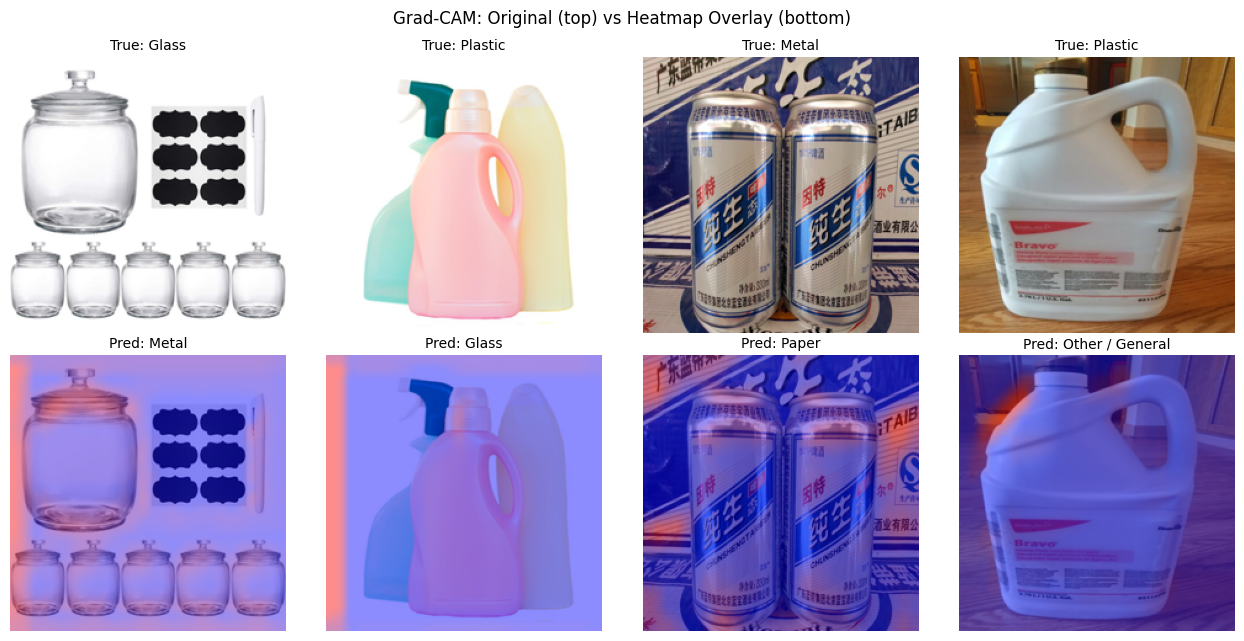

In [15]:
def show_gradcam_examples(model, test_split, class_names, display_names, n=4):
    labels_arr = np.array(test_split["label"])
    idxs = np.random.choice(len(test_split), size=n, replace=False)

    fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 6.5))

    for col, idx in enumerate(idxs):
        example = test_split[int(idx)]
        original = example["image"].convert("RGB").resize((config.IMAGE_SIZE, config.IMAGE_SIZE))
        arr = np.expand_dims(np.asarray(original, dtype=np.float32), axis=0)

        true_label = display_names[example["label"]]

        heatmap, pred_idx = compute_gradcam_heatmap(model, arr)
        overlay = overlay_heatmap(original, heatmap)
        pred_label = display_names[pred_idx]

        axes[0, col].imshow(original)
        axes[0, col].set_title(f"True: {true_label}", fontsize=10)
        axes[0, col].axis("off")

        axes[1, col].imshow(overlay)
        axes[1, col].set_title(f"Pred: {pred_label}", fontsize=10)
        axes[1, col].axis("off")

    plt.suptitle("Grad-CAM: Original (top) vs Heatmap Overlay (bottom)")
    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUTS_DIR, "gradcam_examples.png"), dpi=150)
    plt.show()

show_gradcam_examples(model, test_split, names, display_names)

## 10. Conclusion

This run trained the from scratch CNN on a 5,000 image training subsample
and a 1,000 image validation subsample, for fast CPU iteration, then
evaluated on the complete, untouched test split of 4,478 images.

Test accuracy was 0.4875, with macro precision, recall, and F1 of 0.4866,
0.4885, and 0.4821. Random guessing across six classes would score about
0.17, so the model has learned real signal, but this is a weak result and
should be read as a baseline, not a finished model.

Training accuracy reached about 0.54 while validation accuracy peaked at
0.49, so both are low and close together. That points to underfitting
rather than overfitting: the model is limited by the small training
subset and a small from scratch architecture, not by memorizing the data.
Validation accuracy was also noisy from epoch to epoch, partly because
the validation subset is only 1,000 images.

Per class, cardboard was easiest (F1 0.60), followed by glass (0.53) and
Other / General (0.51). Plastic, metal, and paper were hardest (F1 0.40,
0.42, and 0.42). The most common confusions were plastic predicted as
metal (150 images), plastic as glass (144), and metal as glass (121).
These materials often look alike in photos, for example shiny or
transparent surfaces, which a small CNN trained on limited data struggles
to separate.

Next steps: run the transfer learning backbones (MobileNetV2,
EfficientNetB0, ResNet50) and compare them against this baseline, train
on the full 20,894 image training split with GPU acceleration, and merge
in a dedicated Organic waste dataset as a second pass. Pretrained
backbones are expected to improve on this baseline substantially, but
that should be confirmed with real numbers, not assumed.

Disclaimer: this project is for learning and research purposes only. It
is not a guarantee of correct waste sorting.